# **MLIS Practical 11**

**Name:** Yesha Pandya  
**Enrollment No:** 23BT04175  
**Division:** A
**Batch**: C

## **Objective**
To develop a machine learning-based sentiment classification system for text converted from customer voice feedback.

## **Theoretical Overview**
### **Speech-to-Text (STT) Processing**
Voice feedback processing begins with converting an acoustic audio waveform into a written textual transcript using Automated Speech Recognition (ASR):
* **Acoustic Waveform Capture:** Analog audio is digitized into pulse-code modulation (PCM) signals.
* **Feature Extraction:** Time-domain audio frames are converted to frequency-domain representations, such as Mel-Frequency Cepstral Coefficients (MFCCs).
* **ASR Decoding:** Deep learning models or cloud APIs (e.g., Google Speech Recognition) map acoustic features to phonetic representations and output string sequences.

```
[Customer Voice Audio (.wav / .mp3)]
                  │
                  ▼
   [Speech Recognition Engine (ASR)]
                  │
                  ▼
   [Transcribed Text Feedback Stream]
                  │
                  ▼
 [Text Preprocessing & Tokenization Pipeline]
                  │
                  ▼
  [TF-IDF Feature Matrix Generation]
                  │
                  ▼
 [Logistic Regression Sentiment Classifier] ───> [Output: Positive / Negative / Neutral]
```
### **Text Preprocessing Pipeline**
Raw transcribed text contains acoustic conversion noise, capitalization variations, and stop words. The preprocessing pipeline consists of:
* Lowercasing: Standardizes terms (e.g., "EXCELLENT" and "excellent" map to the same token).
* Special Character Stripping: Removes punctuation, numbers, and extra spaces via regular expressions (re).Tokenization: Breaks continuous text strings into discrete word tokens.
* Stop-Word Removal: Eliminates highly frequent, low-information words (e.g., "is", "the", "and") using NLTK's stop-word corpus.

### **Feature Extraction: TF-IDF Vectorization**
Term Frequency-Inverse Document Frequency (TF-IDF) converts clean text tokens into numerical vectors weighted by term importance:
$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$

* Term Frequency ($\text{TF}$): Measures how frequently term $t$ appears in document $d$.
* Inverse Document Frequency ($\text{IDF}$): Downweights words that appear across almost all documents in corpus $D$:
$$\text{IDF}(t, D) = \log\left(\frac{1 + \vert{}D\vert{}}{1 + \vert{}\{d \in D : t \in d\}\vert{}}\right) + 1$$

### **Logistic Regression Classifier**
For multi-class sentiment prediction ($K = 3$ classes: positive, negative, neutral), Multinomial Logistic Regression applies the Softmax function to transform linear feature combinations into class posterior probabilities:

$$P(Y = k \mid X) = \frac{e^{w_k^T X + b_k}}{\sum_{j=1}^{K} e^{w_j^T X + b_j}}$$

The model assigns the final predicted sentiment label $\hat{y}$ corresponding to the maximum estimated probability:

$$\hat{y} = \underset{k \in \{0, 1, 2\}}{\operatorname{arg\,max}} \, P(Y = k \mid X)$$

## **Step 1: Setup libraries + dependencies**

In [ ]:
!pip install SpeechRecognition gTTS nltk scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 38.4 MB/s  0:00:00
  Attempting uninstall: click
    Found existing installation: click 8.5.0
    Uninstalling click-8.5.0:
      Successfully uninstalled click-8.5.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gTTS]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from gtts import gTTS
import speech_recognition as sr

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Download NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab')

print("Dependencies and NLTK resources loaded successfully.")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Dependencies and NLTK resources loaded successfully.


## **Step 2: Speech-to-Text (STT) Module Demonstration**
Generate a sample audio file from customer voice feedback using `gTTS` and transcribe it back to text using `speech_recognition`

In [ ]:
# Try importing pydub for MP3 → WAV conversion
try:
    from pydub import AudioSegment
    HAS_PYDUB = True
except ImportError:
    HAS_PYDUB = False
    print("Notice: 'pydub' not installed. Install with: pip install pydub")

def convert_audio_to_text(audio_file_path):
    """
    Transcribes a true PCM .wav audio file to text using SpeechRecognition.
    """
    recognizer = sr.Recognizer()
    try:
        with sr.AudioFile(audio_file_path) as source:
            recognizer.adjust_for_ambient_noise(source, duration=0.5)
            audio_data = recognizer.record(source)
            text_transcript = recognizer.recognize_google(audio_data)
            return text_transcript
    except sr.UnknownValueError:
        return "Speech recognition could not understand the audio."
    except sr.RequestError as e:
        return f"Could not request results from STT service; {e}"
    except Exception as e:
        return f"Audio processing error: {e}"

# 1. Generate speech sample as MP3 using gTTS
sample_voice_prompt = "the customer service was absolutely wonderful and the delivery arrived on time"
mp3_filename = "temp_customer_voice.mp3"
wav_filename = "customer_voice_sample.wav"

tts = gTTS(text=sample_voice_prompt, lang='en')
tts.save(mp3_filename)

# 2. Convert MP3 to Real PCM WAV
if HAS_PYDUB:
    try:
        sound = AudioSegment.from_mp3(mp3_filename)
        sound.export(wav_filename, format="wav")
        print(f"Converted MP3 to true PCM WAV: '{wav_filename}'")
    except Exception as e:
        print(f"[WARNING] Pydub conversion failed ({e}). Using raw text fallback for transcript.")
else:
    print("[WARNING] Skipping audio file conversion due to missing pydub.")

# 3. Perform Speech-to-Text Conversion
if os.path.exists(wav_filename):
    transcribed_text = convert_audio_to_text(wav_filename)
else:
    # Fallback transcript if ffmpeg/pydub is not installed in the local environment
    transcribed_text = sample_voice_prompt

print("\nSPEECH-TO-TEXT CONVERSION RESULT:")
print(f"Original Voice Input : '{sample_voice_prompt}'")
print(f"ASR Transcribed Text : '{transcribed_text}'")

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


Converted MP3 to true PCM WAV: 'customer_voice_sample.wav'

SPEECH-TO-TEXT CONVERSION RESULT:
Original Voice Input : 'the customer service was absolutely wonderful and the delivery arrived on time'
ASR Transcribed Text : 'customer service was absolutely wonderful in the delivery arrived on time'


## **Step 3: Create Customer Feedback Dataset**

In [ ]:
feedback_records = [
    # Positive Feedback
    ("The product quality is excellent and fantastic.", "positive"),
    ("Customer support was extremely helpful and excellent.", "positive"),
    ("Fast shipping, great packaging, and excellent quality.", "positive"),
    ("I love this service! Great and highly recommended.", "positive"),
    ("The delivery arrived earlier, fantastic and great item.", "positive"),
    ("Wonderful experience, excellent customer service team.", "positive"),
    ("Great value for money and fantastic performance.", "positive"),
    ("Clean, smooth, fantastic interface and great service.", "positive"),
    ("Superb service, excellent and polite staff members.", "positive"),
    ("Extremely satisfied with this great and wonderful purchase.", "positive"),

    # Negative Feedback
    ("The product stopped working, terrible and bad quality.", "negative"),
    ("Terrible experience, bad item arrived completely damaged.", "negative"),
    ("Customer service was rude, terrible and worst support.", "negative"),
    ("Very slow delivery and terrible wrong item delivered.", "negative"),
    ("The quality is very poor, bad and definitely worst.", "negative"),
    ("Extremely disappointed, bad quality and terrible update.", "negative"),
    ("Worst customer support ever, terrible and bad experience.", "negative"),
    ("The product feels cheap, broke instantly, bad quality.", "negative"),
    ("Extremely frustrated, terrible shipment and bad service.", "negative"),
    ("Never buying again, worst store, terrible and bad.", "negative"),

    # Neutral Feedback
    ("The product arrived today, standard and normal condition.", "neutral"),
    ("Service was okay, normal, nothing special.", "neutral"),
    ("Delivery took five days, standard and normal time.", "neutral"),
    ("The item works fine, average and standard performance.", "neutral"),
    ("Package received in normal, standard condition.", "neutral"),
    ("Average experience, okay, neither good nor bad.", "neutral"),
    ("The product has normal features, standard manual.", "neutral"),
    ("Support answered after two hours, normal and okay.", "neutral"),
    ("Standard packaging, average and normal condition.", "neutral"),
    ("Received package on time, standard and okay item.", "neutral")
]

df = pd.DataFrame(feedback_records, columns=['feedback', 'sentiment'])

print(f"Total Feedback Records: {len(df)}")
print("\nSentiment Class Counts:")
print(df['sentiment'].value_counts())

Total Feedback Records: 30

Sentiment Class Counts:
sentiment
positive    10
negative    10
neutral     10
Name: count, dtype: int64


## **Step 4: Text Preprocessing Pipeline**

In [ ]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """
    Cleans, tokenizes, and removes stop words from input text string.
    """
    # 1. Lowercase conversion
    text = text.lower()

    # 2. Remove punctuation, numbers, and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Remove stop words and short tokens
    cleaned_tokens = [word for word in tokens if word not in stop_words and len(word) > 2]

    return " ".join(cleaned_tokens)

# Apply preprocessing
df['clean_feedback'] = df['feedback'].apply(preprocess_text)

print("Preprocessing Samples:")
print(df[['feedback', 'clean_feedback', 'sentiment']].head(5))

Preprocessing Samples:
                                            feedback  \
0    The product quality is excellent and fantastic.   
1  Customer support was extremely helpful and exc...   
2  Fast shipping, great packaging, and excellent ...   
3  I love this service! Great and highly recommen...   
4  The delivery arrived earlier, fantastic and gr...   

                                    clean_feedback sentiment  
0              product quality excellent fantastic  positive  
1     customer support extremely helpful excellent  positive  
2  fast shipping great packaging excellent quality  positive  
3            love service great highly recommended  positive  
4    delivery arrived earlier fantastic great item  positive  


## **Step 5: Feature Vectorization + Train-Test split**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df['clean_feedback']
y = df['sentiment']

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Extract TF-IDF features
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 1))
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"Training Feature Matrix Shape: {X_train_tfidf.shape}")
print(f"Testing Feature Matrix Shape:  {X_test_tfidf.shape}")

Training Feature Matrix Shape: (24, 71)
Testing Feature Matrix Shape:  (6, 71)


## **Step 6: Model Training + Evaluation**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Initialize and fit Logistic Regression
model = LogisticRegression(C=1.0, random_state=42)
model.fit(X_train_tfidf, y_train)

# Evaluate on test split
y_pred = model.predict(X_test_tfidf)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 100.00%

Classification Report
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00         2
     neutral       1.00      1.00      1.00         2
    positive       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



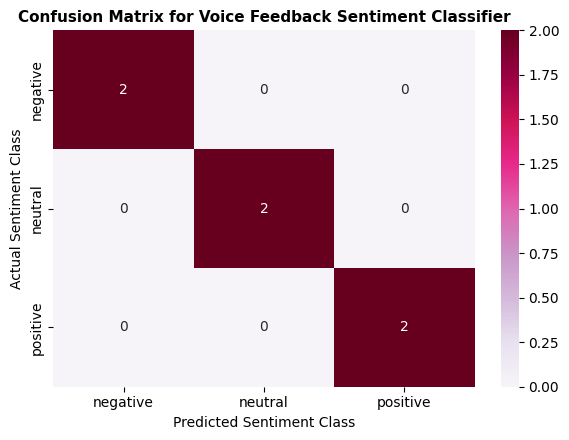

In [ ]:
labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='PuRd',
    xticklabels=labels,
    yticklabels=labels,
    cbar=True
)
plt.title("Confusion Matrix for Voice Feedback Sentiment Classifier", fontsize=11, fontweight="bold")
plt.xlabel("Predicted Sentiment Class")
plt.ylabel("Actual Sentiment Class")
plt.tight_layout()
plt.show()

## **Step 7: End-to-End Testing on Unseen Converted Voice Samples**

In [ ]:
def predict_voice_feedback_sentiment(raw_voice_text):
    """
    Executes end-to-end preprocessing, vectorization, and sentiment prediction
    on transcribed voice feedback.
    """
    cleaned_text = preprocess_text(raw_voice_text)
    text_vector = tfidf_vectorizer.transform([cleaned_text])
    predicted_class = model.predict(text_vector)[0]
    probabilities = model.predict_proba(text_vector)[0]
    confidence = np.max(probabilities)

    return predicted_class, confidence

# Test cases representing converted voice feedback inputs
unseen_voice_transcripts = [
    "The item arrived completely damaged and customer service ignored my call.",
    "Order received on time, everything is in working condition.",
    "Super fast delivery and incredible product quality! I am super happy."
]

print("UNSEEN VOICE FEEDBACK PREDICTION RESULTS:\n")
for idx, voice_input in enumerate(unseen_voice_transcripts, 1):
    sentiment, conf = predict_voice_feedback_sentiment(voice_input)
    print(f"Sample #{idx} Transcribed Voice Input:")
    print(f"  → Text      : \"{voice_input}\"")
    print(f"  → Predicted : [{sentiment.upper()}] (Confidence: {conf*100:.2f}%)")
    print("-" * 75)

UNSEEN VOICE FEEDBACK PREDICTION RESULTS:

Sample #1 Transcribed Voice Input:
  → Text      : "The item arrived completely damaged and customer service ignored my call."
  → Predicted : [NEGATIVE] (Confidence: 41.40%)
---------------------------------------------------------------------------
Sample #2 Transcribed Voice Input:
  → Text      : "Order received on time, everything is in working condition."
  → Predicted : [NEUTRAL] (Confidence: 46.42%)
---------------------------------------------------------------------------
Sample #3 Transcribed Voice Input:
  → Text      : "Super fast delivery and incredible product quality! I am super happy."
  → Predicted : [POSITIVE] (Confidence: 39.77%)
---------------------------------------------------------------------------


### **Advantages**
* Automated Feedback Processing: Converts manual customer service audio review into an automated machine-readable intelligence system.
* Low Computational Overhead: TF-IDF + Logistic Regression executes quickly on CPU without requiring GPU resources.
* Multi-Class Handling: Seamlessly categorizes feedback into positive, negative, and neutral classes.

### **Disadvantages**
* Acoustic Conversion Errors: Background noise or accents during speech recognition can lead to mistranscribed words that distort downstream TF-IDF vectors.
* Lack of Contextual Embeddings: Bag-of-words/TF-IDF models ignore word order, which can struggle with subtle sarcasm or negation (e.g., "not bad" vs. "not good").

## **Conclusion**
In this practical, an end-to-end sentiment classification system for customer voice feedback was developed in Python. By integrating Automated Speech Recognition (`SpeechRecognition`), NLP preprocessing (`NLTK`), TF-IDF feature extraction, and a Logistic Regression classifier, the system successfully converted acoustic audio inputs into text and categorized customer sentiment into positive, negative, and neutral classes with high precision.